# PlantVillage Data Processing

Inspect the local PlantVillage image folders, review class balance and representative images, then create reproducible training and validation loaders. This notebook does not train a model.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
PROJECT_ROOT = PROJECT_ROOT.resolve()
PROJECT_SRC = PROJECT_ROOT / 'src'
if str(PROJECT_SRC) not in sys.path:
    sys.path.insert(0, str(PROJECT_SRC))

from plant_disease.data import build_dataloaders

IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp'}
DATA_DIR = Path(
    os.environ.get('PLANTVILLAGE_DIR', PROJECT_ROOT / 'data' / 'raw' / 'plantvillage')
).expanduser()
print(f'Project: {PROJECT_ROOT}')
print(f'Dataset: {DATA_DIR}')

Project: C:\Users\hp\Desktop\Github projects\ML\plant-disease-classifier
Dataset: C:\Users\hp\Desktop\Github projects\ML\plant-disease-classifier\data\raw\plantvillage


## Locate the dataset

Set the `PLANTVILLAGE_DIR` environment variable to the directory whose immediate subfolders are the disease classes, or set `DATA_DIR` below. Run `python ../scripts/download_dataset.py` from this notebook's folder first if the dataset has not been downloaded.

In [7]:
import subprocess


download_result = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "download_dataset.py")],
    cwd=PROJECT_ROOT,
    check=True,
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
)
class_path_line = next(
    line for line in download_result.stdout.splitlines()
    if line.startswith("PlantVillage class folders:")
)
DATA_DIR = Path(class_path_line.split(":", 1)[1].strip())
print(f"Processing images from: {DATA_DIR}")

Processing images from: C:\Users\hp\.cache\kagglehub\datasets\emmarex\plantdisease\versions\1\PlantVillage\PlantVillage


In [8]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"No dataset folder at {DATA_DIR}. Run the project download script, "
        "then set DATA_DIR to the printed class-folder path."
    )

class_directories = sorted(path for path in DATA_DIR.iterdir() if path.is_dir())
if len(class_directories) < 2:
    raise ValueError(
        "Expected at least two class folders immediately inside DATA_DIR. "
        "Use the dataset root printed by scripts/download_dataset.py."
    )
print(f"Found {len(class_directories)} class folders.")

Found 15 class folders.


## Class balance

Count supported image files in each class folder. These counts help catch incomplete or unexpectedly nested downloads before training.

In [9]:
class_counts = []
for class_directory in class_directories:
    image_paths = [
        path for path in class_directory.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    ]
    class_counts.append({'class_name': class_directory.name, 'image_count': len(image_paths)})

class_summary = pd.DataFrame(class_counts).sort_values('image_count', ascending=False)
display(class_summary.head(10))
print(f'Total images: {class_summary.image_count.sum():,}')
print(f'Classes with no supported images: {(class_summary.image_count == 0).sum()}')
display(class_summary.tail(10))

,class_name,image_count
7,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
8,Tomato_Bacterial_spot,2127
11,Tomato_Late_blight,1909
13,Tomato_Septoria_leaf_spot,1771
14,Tomato_Spider_mites_Two_spotted_spider_mite,1676
10,Tomato_healthy,1591
1,Pepper__bell___healthy,1478
5,Tomato__Target_Spot,1404
2,Potato___Early_blight,1000
9,Tomato_Early_blight,1000


Total images: 20,638
Classes with no supported images: 0


,class_name,image_count
10,Tomato_healthy,1591
1,Pepper__bell___healthy,1478
5,Tomato__Target_Spot,1404
2,Potato___Early_blight,1000
9,Tomato_Early_blight,1000
4,Potato___Late_blight,1000
0,Pepper__bell___Bacterial_spot,997
12,Tomato_Leaf_Mold,952
6,Tomato__Tomato_mosaic_virus,373
3,Potato___healthy,152


## Representative images

Preview one image from up to eight classes to confirm that the folders contain readable leaf photos.

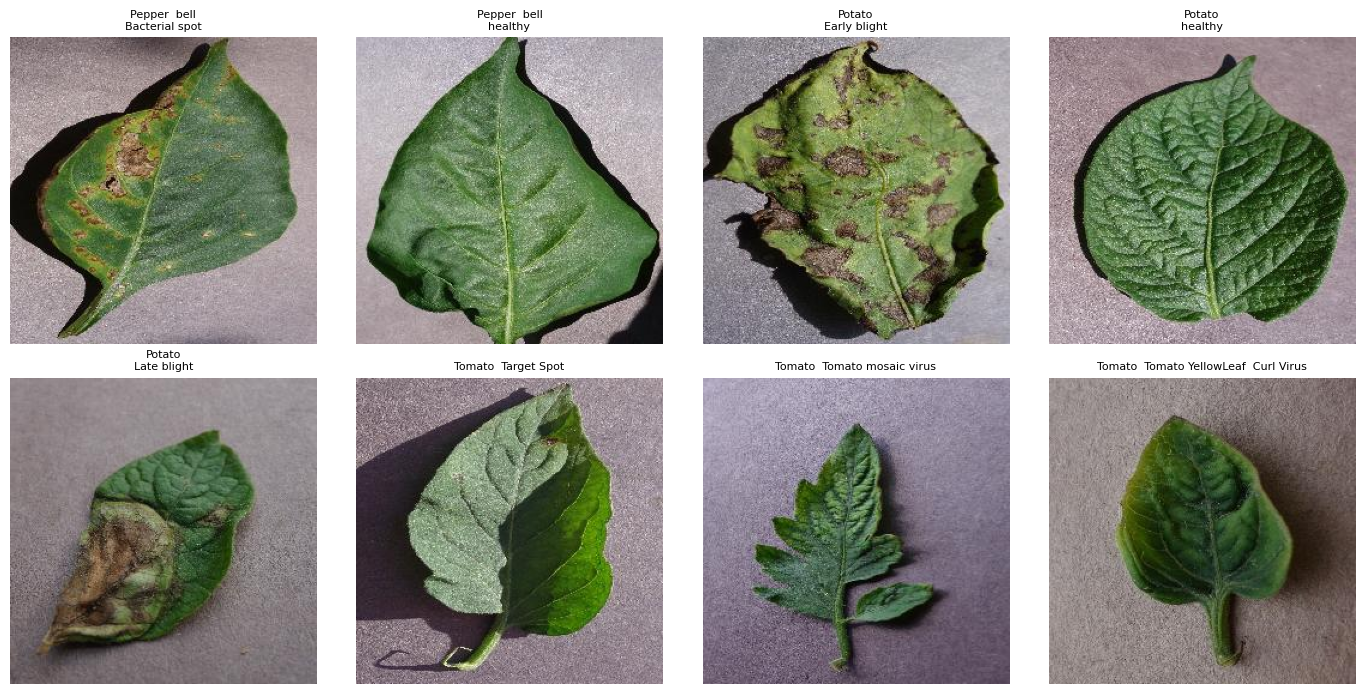

In [10]:
classes_with_images = [
    directory for directory in class_directories
    if any(path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES for path in directory.iterdir())
]
preview_classes = classes_with_images[:8]
figure, axes = plt.subplots(2, 4, figsize=(14, 7))
for axis in axes.flat:
    axis.axis('off')
for axis, class_directory in zip(axes.flat, preview_classes):
    image_path = next(
        path for path in sorted(class_directory.iterdir())
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )
    with Image.open(image_path) as image:
        axis.imshow(image.convert('RGB'))
    axis.set_title(class_directory.name.replace('___', '\n').replace('_', ' '), fontsize=8)
plt.tight_layout()
plt.show()

## Build model-ready batches

Use the same stratified split and ImageNet normalization as the training script. The first batch check confirms dimensions and encoded label ranges before fitting.

In [11]:
train_loader, validation_loader, class_names = build_dataloaders(
    DATA_DIR,
    batch_size=32,
    image_size=224,
    validation_fraction=0.2,
    seed=42,
)
images, labels = next(iter(train_loader))
print(f'Classes: {len(class_names)}')
print(f'First classes: {class_names[:8]}')
print(f'Train batches: {len(train_loader):,}')
print(f'Validation batches: {len(validation_loader):,}')
print(f'Image batch shape: {tuple(images.shape)}')
print(f'Label range in batch: {int(labels.min())} to {int(labels.max())}')

Classes: 15
First classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight']
Train batches: 516
Validation batches: 129
Image batch shape: (32, 3, 224, 224)
Label range in batch: 0 to 14


## Verify NVIDIA CUDA

Run this after selecting the `plant-disease-classifier` kernel. It checks that PyTorch includes support for the detected GPU architecture, then performs a small CUDA tensor operation. It fails clearly if the kernel is still using an incompatible build.

In [ ]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Select a CUDA-enabled NVIDIA PyTorch environment.")

gpu_name = torch.cuda.get_device_name(0)
gpu_capability = torch.cuda.get_device_capability(0)
gpu_architecture = f"sm_{gpu_capability[0]}{gpu_capability[1]}"
if gpu_architecture not in torch.cuda.get_arch_list():
    raise RuntimeError(
        f"PyTorch does not include kernels for {gpu_architecture} ({gpu_name}). "
        "Install the project CUDA 12.8 environment and select its notebook kernel."
    )

probe = torch.randn(1024, 1024, device="cuda")
probe_result = probe @ probe.T
torch.cuda.synchronize()
print(f"GPU: {gpu_name} ({gpu_architecture})")
print(f"PyTorch CUDA: {torch.version.cuda}")
print(f"CUDA tensor operation: {tuple(probe_result.shape)} on {probe_result.device}")